In [36]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
import cv2
from tensorflow.keras import models
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay
from tensorflow.keras.applications import MobileNetV2

In [37]:
# ==========================================
# 2. DOWNLOAD AND CONFIGURE THE DATASET
# ==========================================


import kagglehub

# Download latest version
path = kagglehub.dataset_download("karapy/neurovision")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/karapy/neurovision


In [38]:
DATA = Path('/kaggle/input/datasets/karapy/neurovision/Data/')

In [39]:
# Target image dimensions: 224 pixels high and 224 pixels wide

SIZE = (224, 224)

# Accepted image file extensions

EXTS = {'.jpeg', '.jpg', '.bmp', '.png'}

# Fixed random seed to make data splitting and shuffling reproducible

RANDOM_SEED = 42


# Number of images processed in each batch during training

BATCH = 100

In [40]:
# ==========================================
# 3. IDENTIFY THE IMAGE CLASSES
# ==========================================

# Each subdirectory inside DATA represents an MRI classification category
arr_names = []
for folder in DATA.iterdir():
    arr_names.append(folder.name)

arr_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [41]:
# ==========================================
# 4. COLLECT IMAGE PATHS AND LABELS
# ==========================================


def load_dataset(data_dir=DATA, arr_names=arr_names):

    # Store file paths instead of loading all image pixels into memory

    imgs_path_str, labels = [], []


    for class_name in arr_names:

        image_path = data_dir / class_name

        for path in image_path.iterdir():

            if path.suffix.lower() not in EXTS:
                continue

            imgs_path_str.append(str(path))
            labels.append(class_name)

    # Return NumPy arrays containing paths and their corresponding labels
    
    return np.array(imgs_path_str), np.array(labels)


In [42]:
# Collect image paths and class labels

imgs_path, labels = load_dataset()


# Check the number of collected paths and labels

print(imgs_path.shape, labels.shape)

# Inspect one image path and its corresponding class

print(imgs_path[0])
print(labels[0])

# Count how many images belong to each class

print(np.unique(labels, return_counts=True))

(7023,) (7023,)
/kaggle/input/datasets/karapy/neurovision/Data/glioma/Te-glTr_0000.jpg
glioma
(array(['glioma', 'meningioma', 'notumor', 'pituitary'], dtype='<U10'), array([1621, 1645, 2000, 1757]))


In [43]:
# ==========================================
# 5. ENCODE THE CLASS LABELS
# ==========================================


# Neural networks work with numerical targets rather than text labels

le = LabelEncoder()
labels_int = le.fit_transform(labels)

# Display the mapping between integer labels and original class names

print("Class mapping:", dict(enumerate(le.classes_)))
print(labels_int[:5])

Class mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}
[0 0 0 0 0]


## Split data

In [44]:
# ==========================================
# 6. SPLIT THE DATASET
# ==========================================

# Reserve 80% for training and 20% for temporary data

X_train, X_temp, y_train, y_temp = train_test_split( imgs_path, labels_int, 
                                                            test_size=0.2, 
                                                            stratify=labels_int, 
                                                            random_state=RANDOM_SEED )

# Divide the temporary 20% equally:
# 10% for validation and 10% for testing

X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, 
                                                        test_size=0.5, 
                                                        stratify=y_temp, 
                                                        random_state=RANDOM_SEED )

# Inspect the sizes of the three datasets

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (5618,) (5618,)
Validation: (702,) (702,)
Test: (703,) (703,)


In [45]:
# ==========================================
# 7. CREATE TF.DATA DATASETS
# ==========================================

# Create TensorFlow datasets from image paths and integer labels

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))


In [46]:
# ==========================================
# 8. LOAD AND PREPROCESS IMAGES
# ==========================================


def load_img(path, label):
    img = tf.io.read_file(path)
 
    img = tf.io.decode_image( img, 
                             channels=3, 
                             expand_animations=False )

    # resize the images
    img = tf.image.resize(img, SIZE)

    # normalize pixel values
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)

    return img, label

In [47]:
# ==========================================
# 9. BUILD THE INPUT PIPELINE
# ==========================================

# Training pipeline: map() -> shuffle() -> batch() -> prefetch()

train_ds = train_ds.map(load_img).shuffle(len(X_train), seed=RANDOM_SEED).batch(BATCH).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(load_img).batch(BATCH).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.map(load_img).batch(BATCH).prefetch(tf.data.AUTOTUNE)


# **MobileNetV2**

In [48]:
# ==========================================
# 10. LOAD THE PRETRAINED MOBILENETV2 MODEL
# ==========================================

base_model = MobileNetV2(weights='imagenet',
                         include_top=False,
                         input_shape=(224, 224, 3))

base_model.trainable = False

In [49]:
# ==========================================
# 11. DEFINE TRAINING CALLBACKS
# ==========================================

early_stop = tf.keras.callbacks.EarlyStopping( monitor="val_loss", 
                                              patience=3, 
                                              restore_best_weights=True )

checkpoint = tf.keras.callbacks.ModelCheckpoint('mobilenetv2_mri.keras', save_best_only=True)


In [50]:
# ==========================================
# 12. BUILD THE CLASSIFICATION MODEL
# ==========================================


mobile_model = models.Sequential()
mobile_model.add(base_model)
mobile_model.add(tf.keras.layers.GlobalAveragePooling2D())
mobile_model.add(tf.keras.layers.Dense(128, activation='relu'))
mobile_model.add(tf.keras.layers.Dropout(0.5))
mobile_model.add(tf.keras.layers.Dense(4, activation='softmax'))

mobile_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
# ==========================================
# 13. COMPILE THE MODEL
# ==========================================

mobile_model.compile(optimizer='adam', 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])

In [52]:
# ==========================================
# 14. TRAIN THE MODEL
# ==========================================


mobile_history = mobile_model.fit( train_ds, 
                                  epochs=10, 
                                  validation_data=val_ds, 
                                  verbose=2, 
                                  callbacks=[early_stop, checkpoint] )

Epoch 1/10
57/57 - 33s - 581ms/step - accuracy: 0.7467 - loss: 0.6875 - val_accuracy: 0.8647 - val_loss: 0.3837
Epoch 2/10
57/57 - 12s - 209ms/step - accuracy: 0.8661 - loss: 0.3715 - val_accuracy: 0.8775 - val_loss: 0.2987
Epoch 3/10
57/57 - 12s - 204ms/step - accuracy: 0.8886 - loss: 0.2980 - val_accuracy: 0.8946 - val_loss: 0.2625
Epoch 4/10
57/57 - 12s - 202ms/step - accuracy: 0.9099 - loss: 0.2486 - val_accuracy: 0.9031 - val_loss: 0.2490
Epoch 5/10
57/57 - 11s - 200ms/step - accuracy: 0.9163 - loss: 0.2088 - val_accuracy: 0.9074 - val_loss: 0.2241
Epoch 6/10
57/57 - 11s - 199ms/step - accuracy: 0.9283 - loss: 0.1962 - val_accuracy: 0.9174 - val_loss: 0.2188
Epoch 7/10
57/57 - 11s - 196ms/step - accuracy: 0.9329 - loss: 0.1786 - val_accuracy: 0.9188 - val_loss: 0.2086
Epoch 8/10
57/57 - 11s - 198ms/step - accuracy: 0.9409 - loss: 0.1591 - val_accuracy: 0.9145 - val_loss: 0.1900
Epoch 9/10
57/57 - 12s - 203ms/step - accuracy: 0.9457 - loss: 0.1423 - val_accuracy: 0.9259 - val_loss:

In [53]:
# ==========================================
# 15. MAKE PREDICTIONS ON THE TEST DATASET
# ==========================================

mobile_pred = mobile_model.predict(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 679ms/step


## Fine-tuning 

In [54]:
# ==========================================
# 16. PREPARE THE MODEL FOR FINE-TUNING
# ==========================================

base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False


# ==========================================
# 17. KEEP BATCH NORMALIZATION LAYERS FROZEN
# ==========================================


for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# ==========================================
# 18. RECOMPILE THE MODEL FOR FINE-TUNING
# ==========================================

mobile_model.compile( optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])


# ==========================================
# 19. CONTINUE TRAINING WITH FINE-TUNING
# ==========================================

mobile_history_finetune = mobile_model.fit( train_ds, 
                                           epochs=10, 
                                           validation_data=val_ds, 
                                           callbacks=[early_stop, checkpoint], 
                                           verbose=2 )

Epoch 1/10
57/57 - 37s - 656ms/step - accuracy: 0.9505 - loss: 0.1285 - val_accuracy: 0.9302 - val_loss: 0.1744
Epoch 2/10
57/57 - 13s - 228ms/step - accuracy: 0.9648 - loss: 0.0967 - val_accuracy: 0.9373 - val_loss: 0.1625
Epoch 3/10
57/57 - 13s - 220ms/step - accuracy: 0.9705 - loss: 0.0839 - val_accuracy: 0.9402 - val_loss: 0.1510
Epoch 4/10
57/57 - 13s - 221ms/step - accuracy: 0.9751 - loss: 0.0736 - val_accuracy: 0.9416 - val_loss: 0.1461
Epoch 5/10
57/57 - 12s - 216ms/step - accuracy: 0.9776 - loss: 0.0641 - val_accuracy: 0.9459 - val_loss: 0.1379
Epoch 6/10
57/57 - 12s - 207ms/step - accuracy: 0.9806 - loss: 0.0579 - val_accuracy: 0.9459 - val_loss: 0.1526
Epoch 7/10
57/57 - 12s - 206ms/step - accuracy: 0.9836 - loss: 0.0531 - val_accuracy: 0.9444 - val_loss: 0.1486
Epoch 8/10
57/57 - 12s - 210ms/step - accuracy: 0.9849 - loss: 0.0491 - val_accuracy: 0.9487 - val_loss: 0.1409


## PLots

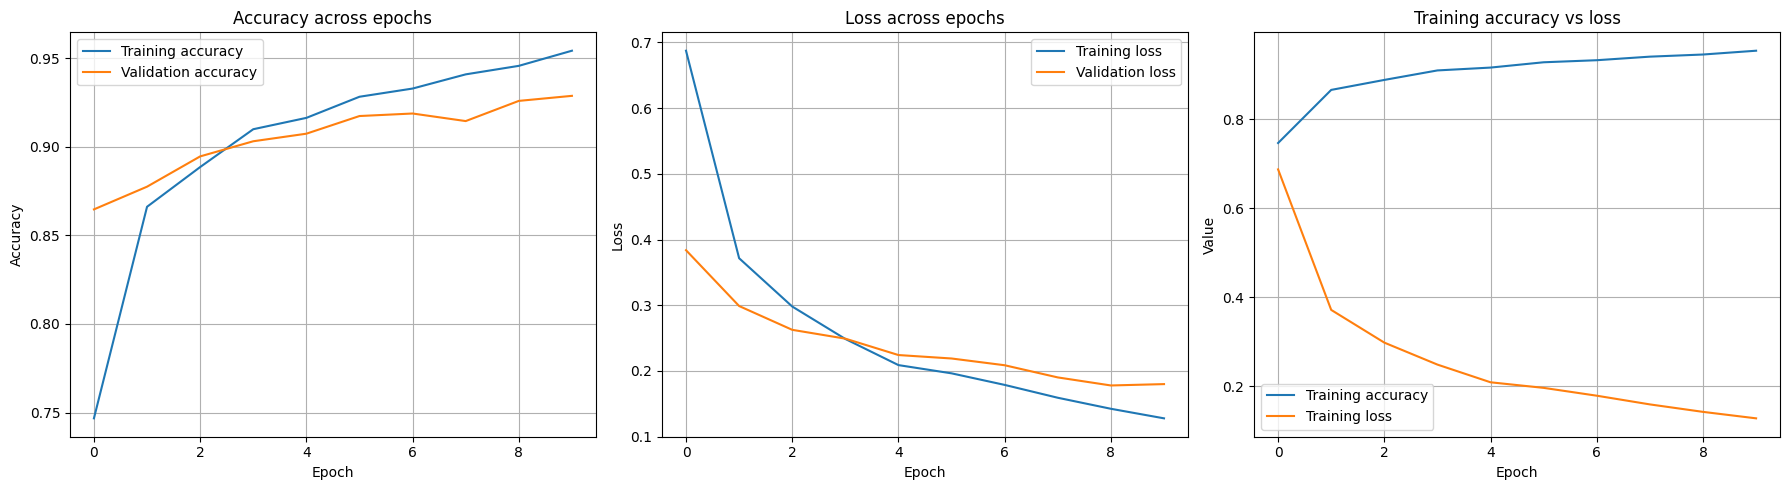

In [ ]:
# ==========================================
# 20. PLOTS
# ==========================================


# Transfer Learning with MobileNetV2 plots 


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Accuracy across epochs
axes[0].plot(mobile_history.history['accuracy'], label='Training accuracy')
axes[0].plot(mobile_history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy across epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# 2. Loss across epochs
axes[1].plot(mobile_history.history['loss'], label='Training loss')
axes[1].plot(mobile_history.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

# 3. Training accuracy vs training loss
axes[2].plot(mobile_history.history['accuracy'], label='Training accuracy')
axes[2].plot(mobile_history.history['loss'], label='Training loss')
axes[2].set_title('Training accuracy vs loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Value')
axes[2].legend()
axes[2].grid(True)

# Adjust spacing to prevent overlapping titles and labels
plt.tight_layout()
plt.show()

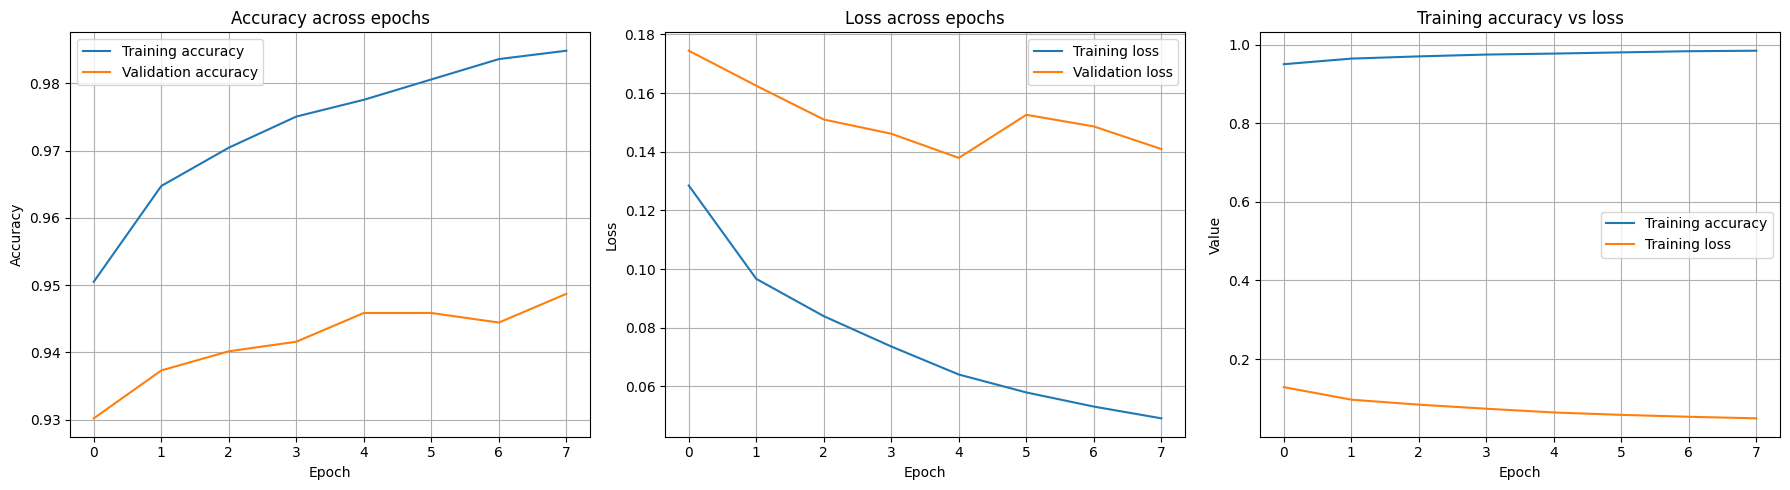

In [ ]:
# fine-tunning with MobileNetV2 plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(mobile_history_finetune.history['accuracy'], label='Training accuracy')
axes[0].plot(mobile_history_finetune.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy across epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(mobile_history_finetune.history['loss'], label='Training loss')
axes[1].plot(mobile_history_finetune.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(mobile_history_finetune.history['accuracy'], label='Training accuracy')
axes[2].plot(mobile_history_finetune.history['loss'], label='Training loss')
axes[2].set_title('Training accuracy vs loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Value')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()